In [ ]:
# Dataset dimensions
print("Number of listings:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of listings: 76534
Number of columns: 16


In [ ]:
# Column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76534 entries, 0 to 76533
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              76534 non-null  int64  
 1   name                            76510 non-null  object 
 2   host_id                         76534 non-null  int64  
 3   host_name                       76488 non-null  object 
 4   neighbourhood_group             0 non-null      float64
 5   neighbourhood                   76534 non-null  object 
 6   latitude                        76534 non-null  float64
 7   longitude                       76534 non-null  float64
 8   room_type                       76534 non-null  object 
 9   price                           76534 non-null  int64  
 10  minimum_nights                  76534 non-null  int64  
 11  number_of_reviews               76534 non-null  int64  
 12  last_review                     

In [ ]:

# Summary statistics
display(df.describe())

,id,host_id,neighbourhood_group,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,7.653400e+04,7.653400e+04,0.0,76534.000000,76534.000000,76534.000000,76534.000000,76534.000000,54340.000000,76534.000000,76534.000000
mean,2.608547e+07,9.737649e+07,NaN,51.510066,-0.128113,113.899051,5.308582,15.207437,0.571656,20.896621,118.742154
std,1.353230e+07,1.026857e+08,NaN,0.047620,0.094883,313.830681,23.053843,35.431784,0.818797,99.725744,143.842762
min,1.391300e+04,2.010000e+03,NaN,51.297330,-0.510220,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,1.526331e+07,1.636504e+07,NaN,51.484460,-0.188308,42.000000,1.000000,0.000000,0.100000,1.000000,0.000000
50%,2.624784e+07,5.012855e+07,NaN,51.514250,-0.125730,75.000000,2.000000,3.000000,0.290000,1.000000,42.000000
75%,3.833904e+07,1.567602e+08,NaN,51.539520,-0.069172,120.000000,4.000000,14.000000,0.730000,4.000000,252.000000
max,4.810299e+07,3.876413e+08,NaN,51.679980,0.288570,17746.000000,1125.000000,821.000000,26.310000,872.000000,365.000000


In [ ]:
# Count listings by room type
display(df['room_type'].value_counts())

,count
room_type,
Entire home/apt,41633
Private room,33734
Shared room,608
Hotel room,559


In [ ]:
# Check missing values
display(df.isnull().sum().sort_values(ascending=False))

,0
neighbourhood_group,76534
reviews_per_month,22194
last_review,22194
host_name,46
name,24
neighbourhood,0
host_id,0
id,0
longitude,0
latitude,0


In [ ]:
clean_df = df.copy()

# Convert price to numeric
clean_df['price'] = pd.to_numeric(clean_df['price'], errors='coerce')

# Remove missing and invalid prices
clean_df = clean_df.dropna(subset=['price', 'room_type'])
clean_df = clean_df[clean_df['price'] > 0]

print("Original listings:", len(df))
print("Listings after cleaning:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

Original listings: 76534
Listings after cleaning: 76510
Rows removed: 24


In [ ]:
print("Mean price:", round(clean_df['price'].mean(), 2))
print("Median price:", round(clean_df['price'].median(), 2))
print("Standard deviation:", round(clean_df['price'].std(), 2))
print("Minimum price:", clean_df['price'].min())
print("Maximum price:", clean_df['price'].max())

display(clean_df['price'].describe())

Mean price: 113.93
Median price: 75.0
Standard deviation: 313.87
Minimum price: 7
Maximum price: 17746


,price
count,76510.000000
mean,113.934780
std,313.873415
min,7.000000
25%,42.000000
50%,75.000000
75%,120.000000
max,17746.000000


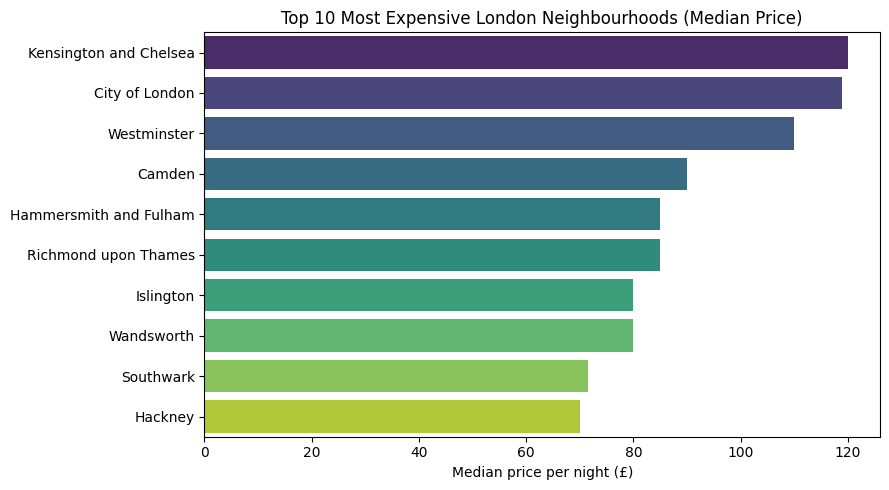

In [ ]:
# 1. Bar chart of the most expensive neighbourhoods
nb = (clean_df.groupby('neighbourhood')['price']
      .agg(['count', 'median'])
      .query('count >= 100')
      .sort_values('median', ascending=False)
      .head(10))

plt.figure(figsize=(9, 5))
sns.barplot(x=nb['median'], y=nb.index, hue=nb.index, palette='viridis', legend=False)
plt.title('Top 10 Most Expensive London Neighbourhoods (Median Price)')
plt.xlabel('Median price per night (£)')
plt.ylabel('')
plt.tight_layout()
plt.savefig('plot_bar_neighbourhood.png', dpi=200)
plt.show()

room_type,Entire home/apt,Hotel room,Private room,Shared room
dist_band,,,,
0-3,140.0,101.0,60.0,30.0
3-6,110.0,110.0,45.0,30.0
6-10,100.0,76.0,40.0,35.0
10-15,97.0,80.0,36.0,40.0
15-20,90.0,NaN,35.0,47.0
20+,95.0,NaN,35.0,NaN


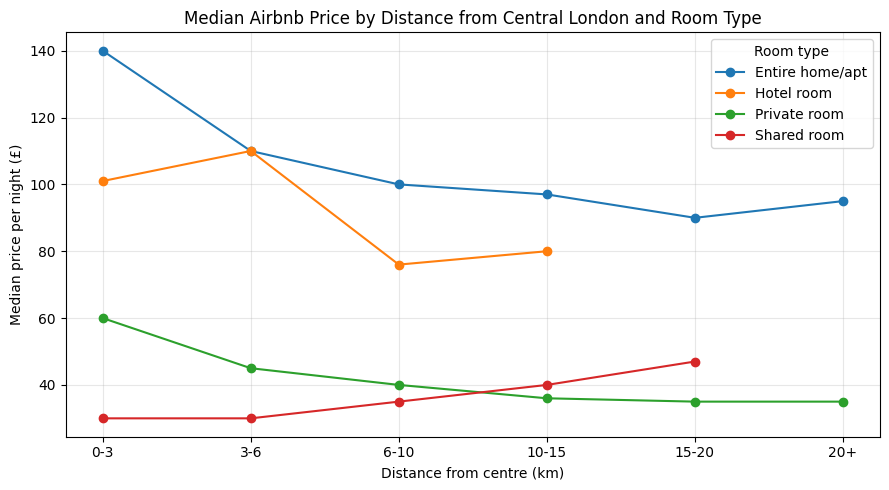

Spearman (price vs distance): -0.316


In [ ]:


# Distance from Charing Cross (assumed centre of London), in km
lat0, lon0 = 51.5074, -0.1278
R = 6371
phi1, phi2 = np.radians(clean_df['latitude']), np.radians(lat0)
dphi = phi2 - phi1
dlmb = np.radians(lon0 - clean_df['longitude'])
a = np.sin(dphi/2)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlmb/2)**2
clean_df['dist_km'] = 2 * R * np.arcsin(np.sqrt(a))

clean_df['dist_band'] = pd.cut(clean_df['dist_km'],
                               bins=[0, 3, 6, 10, 15, 20, 100],
                               labels=['0-3', '3-6', '6-10', '10-15', '15-20', '20+'])

# Median price per distance band and room type (skip groups with fewer than 30 listings)
g = (clean_df.groupby(['dist_band', 'room_type'], observed=True)['price']
     .agg(['count', 'median']).reset_index())
g = g[g['count'] >= 30]
pivot = g.pivot(index='dist_band', columns='room_type', values='median')
pivot.index = pivot.index.astype(str)
display(pivot.round(0))

ax = pivot.plot(marker='o', figsize=(9, 5))
ax.set(title='Median Airbnb Price by Distance from Central London and Room Type',
       xlabel='Distance from centre (km)', ylabel='Median price per night (£)')
ax.grid(alpha=0.3)
ax.legend(title='Room type')
plt.tight_layout()
plt.savefig('plot_distance_roomtype.png', dpi=200)
plt.show()

print("Spearman (price vs distance):",
      round(clean_df['price'].corr(clean_df['dist_km'], method='spearman'), 3))

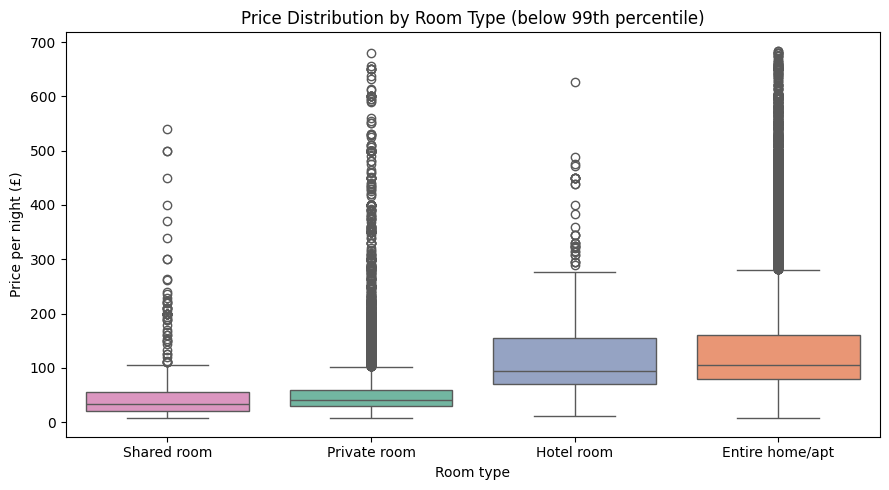

,count,median,mean
room_type,,,
Entire home/apt,41633,108.0,157.3
Hotel room,538,95.0,124.6
Private room,33731,40.0,61.2
Shared room,608,33.5,62.6


In [ ]:
#box plot of price by room type

cap = clean_df['price'].quantile(0.99)
order = clean_df[clean_df['price'] <= cap].groupby('room_type')['price'].median().sort_values().index

plt.figure(figsize=(9, 5))
sns.boxplot(data=clean_df[clean_df['price'] <= cap], x='room_type', y='price',
            order=order, hue='room_type', palette='Set2', legend=False)
plt.title('Price Distribution by Room Type (below 99th percentile)')
plt.xlabel('Room type')
plt.ylabel('Price per night (£)')
plt.tight_layout()
plt.savefig('plot_box_roomtype.png', dpi=200)
plt.show()

display(clean_df.groupby('room_type')['price'].agg(['count', 'median', 'mean']).round(1))